INTRODUCTION

In [5]:
import pandas as pd

file_path = "Superstore.xls"

df = pd.read_excel("/Users/enayath/Downloads/Superstore.xls", sheet_name="Orders")


DATASET OVERVIEW

In [7]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
print(df.head())

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [9]:
# Check whether Row ID is unique
print("Total rows:", len(df))
print("Unique Row IDs:", df["Row ID"].nunique())
print("Missing Row IDs:", df["Row ID"].isnull().sum())
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())


Total rows: 9994
Unique Row IDs: 9994
Missing Row IDs: 0
Duplicate Row IDs: 0


In [11]:
 #Validate the remaining identifier columns
id_columns = ["Order ID", "Customer ID", "Product ID"]

for col in id_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print("Missing values:", df[col].isnull().sum())
    print("Repeated rows:", df[col].duplicated().sum())



Order ID
Unique values: 5009
Missing values: 0
Repeated rows: 4985

Customer ID
Unique values: 793
Missing values: 0
Repeated rows: 9201

Product ID
Unique values: 1862
Missing values: 0
Repeated rows: 8132


In [14]:
#NUMERICAL COLS
# Check for completely identical rows
exact_duplicates = df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)
numerical_columns = ["Sales", "Profit", "Discount", "Quantity"]
print(df[numerical_columns].describe())

print("Unique discount values:")
print(sorted(df["Discount"].unique()))

Exact duplicate rows: 0
              Sales       Profit     Discount     Quantity
count   9994.000000  9994.000000  9994.000000  9994.000000
mean     229.858001    28.656896     0.156203     3.789574
std      623.245101   234.260108     0.206452     2.225110
min        0.444000 -6599.978000     0.000000     1.000000
25%       17.280000     1.728750     0.000000     2.000000
50%       54.490000     8.666500     0.200000     3.000000
75%      209.940000    29.364000     0.200000     5.000000
max    22638.480000  8399.976000     0.800000    14.000000
Unique discount values:
[np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.32), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]


In [16]:
#detecting outliers
for col in ["Sales", "Profit"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{col}")
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Potential outlier records:", len(outliers))



Sales
Lower bound: -271.71000000000004
Upper bound: 498.93
Potential outlier records: 1167

Profit
Lower bound: -39.724124999999994
Upper bound: 70.81687499999998
Potential outlier records: 1881


In [18]:
#sorting
print(df['Sales'].sort_values(ascending=False))
print(df.loc[df['Sales']==22638.480,['Category','Sub-Category','Product Name','Quantity']])

cols = [
    'Order ID', 'Category', 'Sub-Category',
    'Product Name', 'Quantity', 'Discount',
    'Sales', 'Profit'
]

print(df.nlargest(5, 'Sales')[cols].to_string(index=False))

print(df.nlargest(5, 'Sales')[['Order ID', 'Product Name', 'Sales']].to_string(index=False))

2697    22638.480
6826    17499.950
8153    13999.960
2623    11199.968
4190    10499.970
          ...    
2106        0.876
4711        0.852
8658        0.836
9292        0.556
4101        0.444
Name: Sales, Length: 9994, dtype: float64
        Category Sub-Category  \
2697  technology     machines   

                                           Product Name  Quantity  
2697  cisco telepresence system ex90 videoconferenci...         6  
      Order ID   Category Sub-Category                                          Product Name  Quantity  Discount     Sales     Profit
ca-2014-145317 technology     machines cisco telepresence system ex90 videoconferencing unit         6       0.5 22638.480 -1811.0784
ca-2016-118689 technology      copiers                 canon imageclass 2200 advanced copier         5       0.0 17499.950  8399.9760
ca-2017-140151 technology      copiers                 canon imageclass 2200 advanced copier         4       0.0 13999.960  6719.9808
ca-2017-127180 techno

In [20]:
cols = [
    'Order ID',
    'Product Name',
    'Category',
    'Quantity',
    'Discount',
    'Sales',
    'Profit'
]

print(df.nlargest(5, 'Sales')[cols].to_string(index=False))


      Order ID                                          Product Name   Category  Quantity  Discount     Sales     Profit
ca-2014-145317 cisco telepresence system ex90 videoconferencing unit technology         6       0.5 22638.480 -1811.0784
ca-2016-118689                 canon imageclass 2200 advanced copier technology         5       0.0 17499.950  8399.9760
ca-2017-140151                 canon imageclass 2200 advanced copier technology         4       0.0 13999.960  6719.9808
ca-2017-127180                 canon imageclass 2200 advanced copier technology         4       0.2 11199.968  3919.9888
ca-2017-166709                 canon imageclass 2200 advanced copier technology         3       0.0 10499.970  5039.9856


In [22]:
print(
    df.nsmallest(5, 'Sales')[
        ['Order ID', 'Product Name', 'Quantity', 'Sales']
    ].to_string(index=False)

)


      Order ID                                                               Product Name  Quantity  Sales
us-2017-102288 hoover replacement belt for commercial guardsman heavy-duty upright vacuum         1  0.444
ca-2017-124114                                   acco suede grain vinyl round ring binder         1  0.556
ca-2016-168361                         avery durable slant ring binders with label holder         1  0.836
ca-2014-112403                                              avery round ring poly binders         1  0.852
us-2014-152723                                                          acco 3-hole punch         1  0.876


In [24]:
# Calculate IQR bounds for Sales
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [31]:
# Store potential Sales outliers separately
sales_outliers = df[
    (df['Sales'] < lower) | (df['Sales'] > upper)
].copy()

print("Potential Sales outliers:", len(sales_outliers))
print("\nSales outlier summary:")
print(sales_outliers['Sales'].describe())

Potential Sales outliers: 4455

Sales outlier summary:
count     4455.000000
mean       484.841698
std        868.185985
min         70.880000
25%        127.764000
50%        244.615000
75%        523.326000
max      22638.480000
Name: Sales, dtype: float64


In [32]:
print("\nHighest Sales values:")
print(sales_outliers.nlargest(10, 'Sales')[
    ['Order ID', 'Product Name', 'Quantity', 'Sales']
].to_string(index=False))


Highest Sales values:
      Order ID                                              Product Name  Quantity     Sales
ca-2014-145317     cisco telepresence system ex90 videoconferencing unit         6 22638.480
ca-2016-118689                     canon imageclass 2200 advanced copier         5 17499.950
ca-2017-140151                     canon imageclass 2200 advanced copier         4 13999.960
ca-2017-127180                     canon imageclass 2200 advanced copier         4 11199.968
ca-2017-166709                     canon imageclass 2200 advanced copier         3 10499.970
ca-2016-117121          gbc ibimaster 500 manual proclick binding system        13  9892.740
ca-2014-116904                      ibico epk-21 electric binding system         5  9449.950
us-2016-107440          3d systems cube printer, 2nd generation, magenta         7  9099.930
ca-2016-158841 hp designjet t520 inkjet large format printer - 24" color         5  8749.950
ca-2016-143714                     canon imagec

In [33]:
print("\nLowest Sales values among flagged records:")
print(sales_outliers.nsmallest(10, 'Sales')[
    ['Order ID', 'Product Name', 'Quantity', 'Sales']
].to_string(index=False))


Lowest Sales values among flagged records:
      Order ID                                               Product Name  Quantity  Sales
ca-2016-158869                                          easy-staple paper         2  70.88
ca-2016-106460                                                 xerox 1880         2  70.88
ca-2016-115756  eldon mobile mega data cart  mega stackable  add-on trays         3  70.95
ca-2017-147725 boston home & office model 2000 electric pencil sharpeners         3  70.95
ca-2015-138954  eldon mobile mega data cart  mega stackable  add-on trays         3  70.95
ca-2014-153808 boston home & office model 2000 electric pencil sharpeners         3  70.95
ca-2015-129217             tripp lite isotel 8 ultra 8 outlet metal surge         5  70.97
ca-2015-128139                   novimex high-tech fabric mesh task chair         1  70.98
ca-2016-133711                                          easy-staple paper         7  70.98
ca-2017-142888                                

In [35]:
sales_outliers['Sales_per_Unit'] = (
    sales_outliers['Sales'] / sales_outliers['Quantity']
)

In [47]:
print(
    sales_outliers.nlargest(10, 'Sales_per_Unit')[
        ['Order ID', 'Product Name', 'Quantity', 'Sales', 'Sales_per_Unit']
    ].to_string(index=False)
)

      Order ID                                                          Product Name  Quantity     Sales  Sales_per_Unit
CA-2014-145317                 Cisco TelePresence System EX90 Videoconferencing Unit         6 22638.480        3773.080
CA-2017-166709                                 Canon imageCLASS 2200 Advanced Copier         3 10499.970        3499.990
CA-2017-140151                                 Canon imageCLASS 2200 Advanced Copier         4 13999.960        3499.990
CA-2016-118689                                 Canon imageCLASS 2200 Advanced Copier         5 17499.950        3499.990
CA-2017-127180                                 Canon imageCLASS 2200 Advanced Copier         4 11199.968        2799.992
CA-2017-149881                             Cubify CubeX 3D Printer Double Head Print         2  4799.984        2399.992
CA-2016-143714                                 Canon imageCLASS 2200 Advanced Copier         4  8399.976        2099.994
US-2017-168116                  

In [48]:
print(
    sales_outliers.groupby('Product Name')
    .agg(
        Record_Count=('Sales', 'size'),
        Min_Sales=('Sales', 'min'),
        Max_Sales=('Sales', 'max'),
        Min_Quantity=('Quantity', 'min'),
        Max_Quantity=('Quantity', 'max')
    )
    .sort_values('Record_Count', ascending=False)
    .head(10)
    .to_string()
)

                                                                             Record_Count  Min_Sales  Max_Sales  Min_Quantity  Max_Quantity
Product Name                                                                                                                               
GBC DocuBind TL300 Electric Binding System                                             11    538.194   4305.552             1             6
Tennsco Double-Tier Lockers                                                            10    540.048   1575.140             3             7
Bretford Rectangular Conference Table Tops                                             10    526.582   3610.848             2            12
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind            10    762.594   6354.950             1             6
SAFCO Arco Folding Chair                                                               10    662.880   1740.060             3             9
Tennsco 6- and 18-Co

In [49]:
product = 'GBC DocuBind TL300 Electric Binding System'

print(
    df.loc[df['Product Name'] == product,
           ['Order ID', 'Quantity', 'Sales']]
    .sort_values('Sales', ascending=False)
    .to_string(index=False)
)

Empty DataFrame
Columns: [Order ID, Quantity, Sales]
Index: []


In [50]:
product = 'GBC DocuBind TL300 Electric Binding System'

print(
    df.loc[
        df['Product Name'] == product,
        ['Order ID', 'Quantity', 'Discount', 'Sales', 'Profit']
    ]
    .sort_values('Quantity')
    .to_string(index=False)
)

Empty DataFrame
Columns: [Order ID, Quantity, Discount, Sales, Profit]
Index: []


In [51]:
#profit
Q1 = df['Profit'].quantile(0.25)
Q3 = df['Profit'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

profit_outliers = df[
    (df['Profit'] < lower) | (df['Profit'] > upper)
].copy()

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Potential Profit outliers:", len(profit_outliers))


Lower bound: -39.724124999999994
Upper bound: 70.81687499999998
Potential Profit outliers: 1881


In [53]:
print(
    profit_outliers.nsmallest(10, 'Profit')[
        ['Order ID', 'Product Name', 'Category',
         'Quantity', 'Sales', 'Profit']
    ].to_string(index=False)
)


      Order ID                                                                Product Name        Category  Quantity     Sales     Profit
CA-2016-108196                                   Cubify CubeX 3D Printer Double Head Print      Technology         5  4499.985 -6599.9780
US-2017-168116                                   Cubify CubeX 3D Printer Triple Head Print      Technology         4  7999.980 -3839.9904
CA-2014-169019                                   GBC DocuBind P400 Electric Binding System Office Supplies         8  2177.584 -3701.8928
CA-2017-134845                                   Lexmark MX611dhe Monochrome Laser Printer      Technology         5  2549.985 -3399.9800
US-2017-122714                                        Ibico EPK-21 Electric Binding System Office Supplies         5  1889.990 -2929.4845
CA-2015-147830                                   Cubify CubeX 3D Printer Double Head Print      Technology         2  1799.994 -2639.9912
CA-2017-131254 Fellowes PB500 Elec

In [59]:
cols = [
    'Order ID',
    'Product Name',
    'Quantity',
    'Discount',
    'Sales',
    'Profit'
]

print(
    profit_outliers.nsmallest(10, 'Profit')[cols]
    .to_string(index=False)
)

      Order ID                                                                Product Name  Quantity  Discount     Sales     Profit
CA-2016-108196                                   Cubify CubeX 3D Printer Double Head Print         5       0.7  4499.985 -6599.9780
US-2017-168116                                   Cubify CubeX 3D Printer Triple Head Print         4       0.5  7999.980 -3839.9904
CA-2014-169019                                   GBC DocuBind P400 Electric Binding System         8       0.8  2177.584 -3701.8928
CA-2017-134845                                   Lexmark MX611dhe Monochrome Laser Printer         5       0.7  2549.985 -3399.9800
US-2017-122714                                        Ibico EPK-21 Electric Binding System         5       0.8  1889.990 -2929.4845
CA-2015-147830                                   Cubify CubeX 3D Printer Double Head Print         2       0.7  1799.994 -2639.9912
CA-2017-131254 Fellowes PB500 Electric Punch Plastic Comb Binding Machine wi

In [60]:
product = 'Cubify CubeX 3D Printer Double Head Print'

print(
    df.loc[
        df['Product Name'] == product,
        ['Order ID', 'Quantity', 'Discount', 'Sales', 'Profit']
    ]
    .sort_values('Profit')
    .to_string(index=False)
)

Empty DataFrame
Columns: [Order ID, Quantity, Discount, Sales, Profit]
Index: []


In [61]:
print("Sales <= 0:", (df['Sales'] <= 0).sum())

print("Quantity <= 0:", (df['Quantity'] <= 0).sum())

print(
    "Non-integer quantities:",
    (df['Quantity'] % 1 != 0).sum()
)

print(
    "Discount outside 0-1:",
    ((df['Discount'] < 0) | (df['Discount'] > 1)).sum()
)

print(df[['Sales', 'Profit', 'Quantity', 'Discount']].isnull().sum())

Sales <= 0: 0
Quantity <= 0: 0
Non-integer quantities: 0
Discount outside 0-1: 0
Sales       0
Profit      0
Quantity    0
Discount    0
dtype: int64


In [63]:
#date
print("Missing Order Dates:", df['Order Date'].isnull().sum())
print("Missing Ship Dates:", df['Ship Date'].isnull().sum())

print(
    "Orders shipped before order date:",
    (df['Ship Date'] < df['Order Date']).sum()
)

Missing Order Dates: 0
Missing Ship Dates: 0
Orders shipped before order date: 0


In [80]:
#categorical cols
categorical_columns = df.select_dtypes(
    include=['object', 'str']
).columns


In [81]:
for col in categorical_columns:
    df[col] = df[col].str.strip().str.lower()


In [82]:
#to check
for col in categorical_columns:
    print(
        col,
        ":",
        (df[col] != df[col].str.strip()).sum()
    )


Order ID : 0
Ship Mode : 0
Customer ID : 0
Customer Name : 0
Segment : 0
Country : 0
City : 0
State : 0
Postal Code : 0
Region : 0
Product ID : 0
Category : 0
Sub-Category : 0
Product Name : 0


In [83]:
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


Order ID:
<StringArray>
['ca-2016-152156', 'ca-2016-138688', 'us-2015-108966', 'ca-2014-115812',
 'ca-2017-114412', 'ca-2016-161389', 'us-2015-118983', 'ca-2014-105893',
 'ca-2014-167164', 'ca-2014-143336',
 ...
 'us-2016-103674', 'us-2015-151435', 'ca-2017-163566', 'us-2016-157728',
 'ca-2015-100251', 'ca-2016-125794', 'ca-2017-163629', 'ca-2014-110422',
 'ca-2017-121258', 'ca-2017-119914']
Length: 5009, dtype: str

Ship Mode:
<StringArray>
['second class', 'standard class', 'first class', 'same day']
Length: 4, dtype: str

Customer ID:
<StringArray>
['cg-12520', 'dv-13045', 'so-20335', 'bh-11710', 'aa-10480', 'im-15070',
 'hp-14815', 'pk-19075', 'ag-10270', 'zd-21925',
 ...
 'fw-14395', 'lc-16960', 'he-14800', 'bd-11560', 'hd-14785', 'cj-11875',
 'rs-19870', 'sc-20845', 're-19405', 'sm-20905']
Length: 793, dtype: str

Customer Name:
<StringArray>
[       'claire gute',    'darrin van huff',     'sean o'donnell',
    'brosina hoffman',       'andrew allen',       'irene maddox',
    

In [84]:
check_columns = [
    'Ship Mode',
    'Segment',
    'Region',
    'Category',
    'Sub-Category'
]
for col in check_columns:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique()))

print("Missing City values:", df["City"].isnull().sum())
print("Missing State values:", df["State"].isnull().sum())



Ship Mode:
['first class', 'same day', 'second class', 'standard class']

Segment:
['consumer', 'corporate', 'home office']

Region:
['central', 'east', 'south', 'west']

Category:
['furniture', 'office supplies', 'technology']

Sub-Category:
['accessories', 'appliances', 'art', 'binders', 'bookcases', 'chairs', 'copiers', 'envelopes', 'fasteners', 'furnishings', 'labels', 'machines', 'paper', 'phones', 'storage', 'supplies', 'tables']
Missing City values: 0
Missing State values: 0


In [86]:
print("\nUnique cities:", df["City"].nunique())
print("Unique states:", df["State"].nunique())


Unique cities: 531
Unique states: 49


In [88]:
df.info()
df["Postal Code"] = df["Postal Code"].astype(str)
df.info()

print(df.info())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())

print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   str           
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [90]:
#EDA

numeric_cols = ['Sales', 'Quantity', 'Discount', 'Profit']

summary = df[numeric_cols].describe().T
summary['median'] = df[numeric_cols].median()
summary['IQR'] = summary['75%'] - summary['25%']
summary['skewness'] = df[numeric_cols].skew()

print("Numeric Summary Statistics:\n")
print(summary)


Numeric Summary Statistics:

           count        mean         std       min       25%      50%  \
Sales     9994.0  229.858001  623.245101     0.444  17.28000  54.4900   
Quantity  9994.0    3.789574    2.225110     1.000   2.00000   3.0000   
Discount  9994.0    0.156203    0.206452     0.000   0.00000   0.2000   
Profit    9994.0   28.656896  234.260108 -6599.978   1.72875   8.6665   

              75%        max   median        IQR   skewness  
Sales     209.940  22638.480  54.4900  192.66000  12.972752  
Quantity    5.000     14.000   3.0000    3.00000   1.278545  
Discount    0.200      0.800   0.2000    0.20000   1.684295  
Profit     29.364   8399.976   8.6665   27.63525   7.561432  


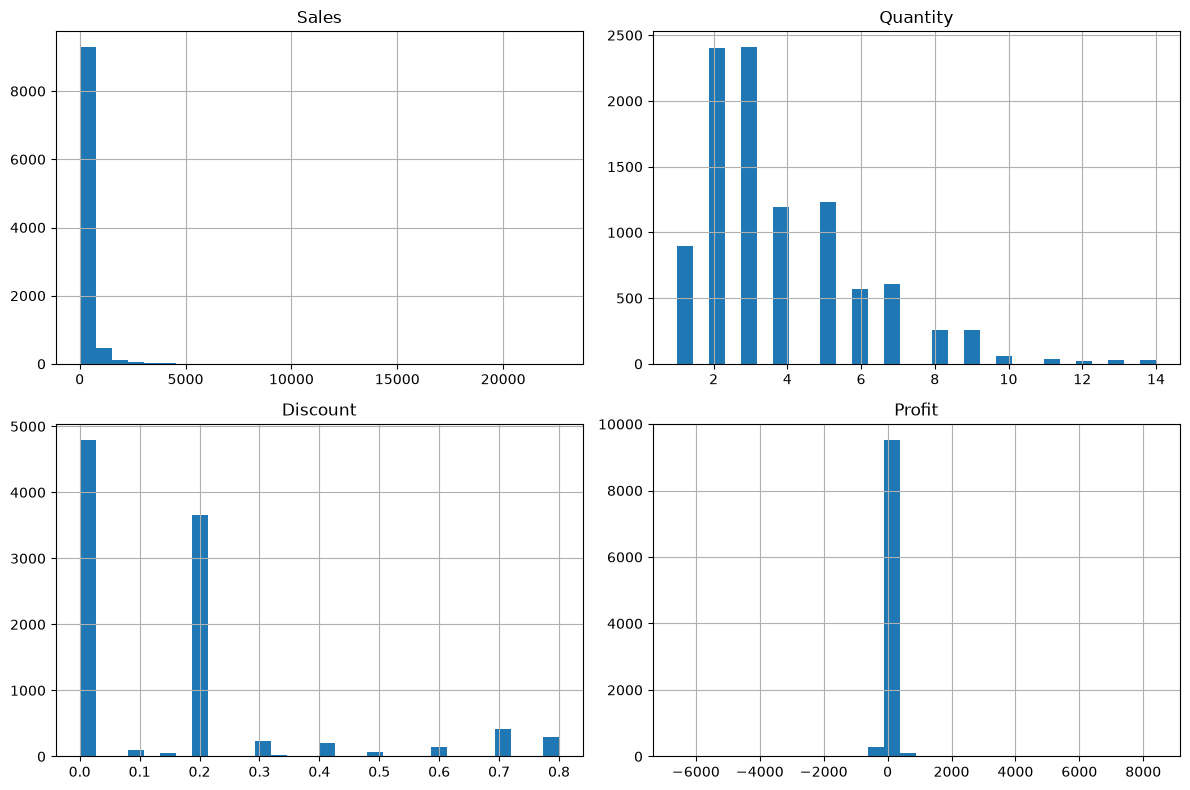

None


In [92]:

import matplotlib.pyplot as plt

df[numeric_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
print(plt.show())

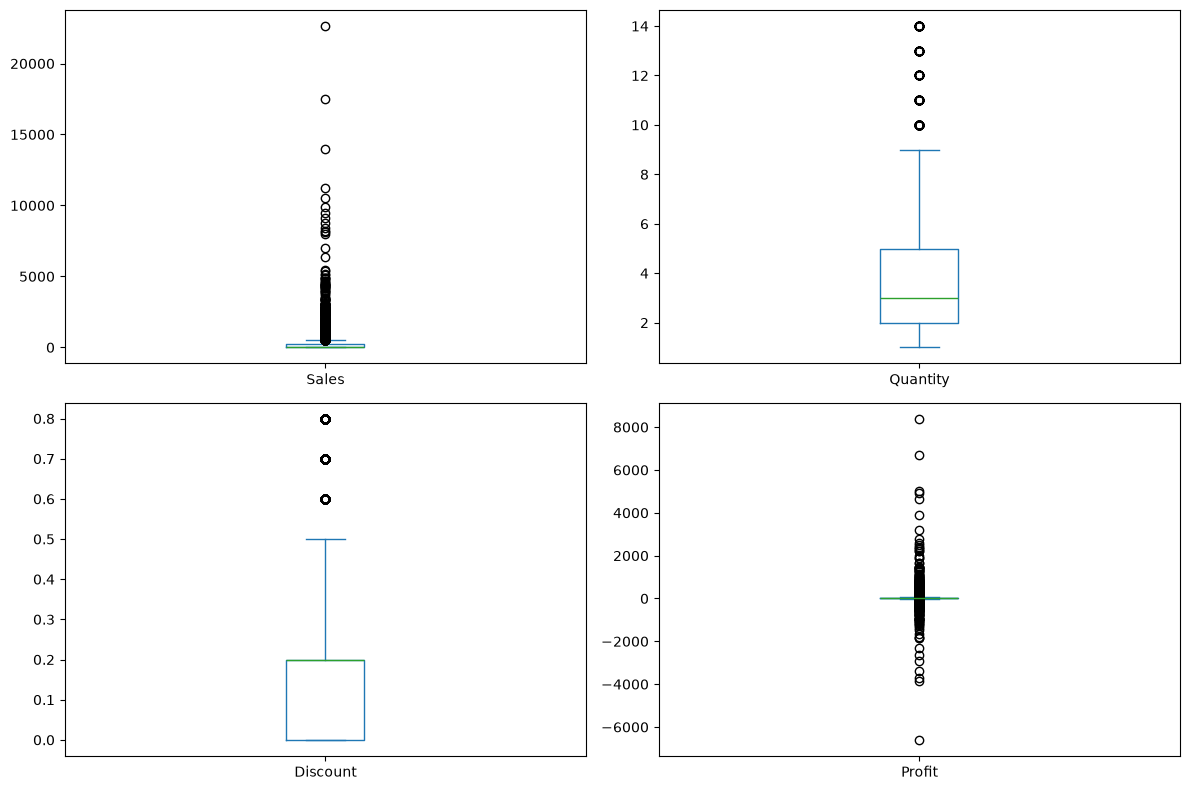

None


In [94]:
df[numeric_cols].plot(
    kind='box',
    subplots=True,
    layout=(2, 2),
    figsize=(12, 8)
)

plt.tight_layout()
print(plt.show())

In [100]:
for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))




Order ID
Order ID
ca-2017-100111    14
ca-2017-157987    12
us-2016-108504    11
ca-2016-165330    11
ca-2015-131338    10
us-2015-126977    10
ca-2016-105732    10
ca-2017-117457     9
ca-2014-106439     9
ca-2015-164882     9
Name: count, dtype: int64

Ship Mode
Ship Mode
standard class    5968
second class      1945
first class       1538
same day           543
Name: count, dtype: int64

Customer ID
Customer ID
wb-21850    37
ma-17560    34
jl-15835    34
pp-18955    34
jd-15895    32
ck-12205    32
sv-20365    32
eh-13765    32
ep-13915    31
zc-21910    31
Name: count, dtype: int64

Customer Name
Customer Name
william brown          37
matt abelman           34
john lee               34
paul prost             34
jonathan doherty       32
chloris kastensmidt    32
seth vernon            32
edward hooks           32
emily phan             31
zuschuss carroll       31
Name: count, dtype: int64

Segment
Segment
consumer       5191
corporate      3020
home office    1783
Name: count, 

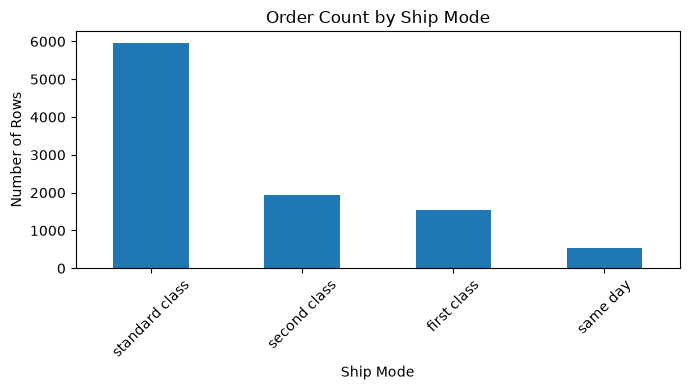

None


In [101]:
df['Ship Mode'].value_counts().plot(
    kind='bar',
    figsize=(7, 4),
    title='Order Count by Ship Mode'
)

plt.xlabel('Ship Mode')
plt.ylabel('Number of Rows')
plt.xticks(rotation=45)
plt.tight_layout()
print(plt.show())

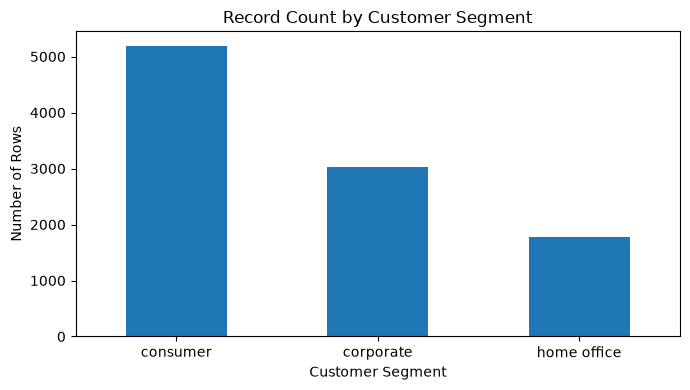

None


In [103]:
df['Segment'].value_counts().plot(
    kind='bar',
    figsize=(7, 4),
    title='Record Count by Customer Segment'
)

plt.xlabel('Customer Segment')
plt.ylabel('Number of Rows')
plt.xticks(rotation=0)
plt.tight_layout()
print(plt.show())

      Row ID        Order ID Order Date  Ship Date       Ship Mode  \
0          1  ca-2016-152156 2016-11-08 2016-11-11    second class   
1          2  ca-2016-152156 2016-11-08 2016-11-11    second class   
2          3  ca-2016-138688 2016-06-12 2016-06-16    second class   
3          4  us-2015-108966 2015-10-11 2015-10-18  standard class   
4          5  us-2015-108966 2015-10-11 2015-10-18  standard class   
...      ...             ...        ...        ...             ...   
9989    9990  ca-2014-110422 2014-01-21 2014-01-23    second class   
9990    9991  ca-2017-121258 2017-02-26 2017-03-03  standard class   
9991    9992  ca-2017-121258 2017-02-26 2017-03-03  standard class   
9992    9993  ca-2017-121258 2017-02-26 2017-03-03  standard class   
9993    9994  ca-2017-119914 2017-05-04 2017-05-09    second class   

     Customer ID     Customer Name    Segment        Country             City  \
0       cg-12520       claire gute   consumer  united states        henderson 

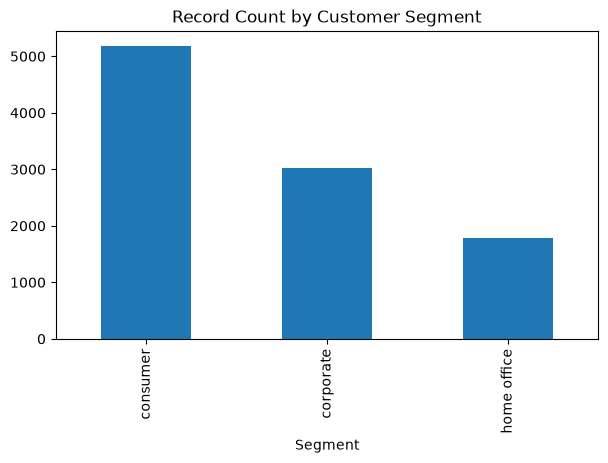

In [105]:
df['Segment'].value_counts().plot(
    kind='bar',
    figsize=(7, 4),
    title='Record Count by Customer Segment'
)
print(df)


In [107]:
print("Product Category Record Counts:")
print(df['Category'].value_counts())


Product Category Record Counts:
Category
office supplies    6026
furniture          2121
technology         1847
Name: count, dtype: int64


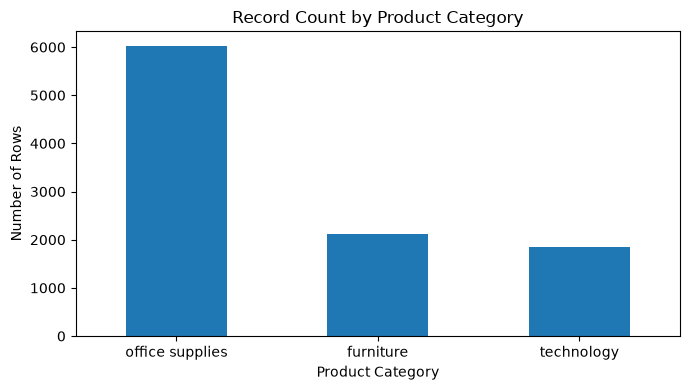

None


In [109]:
df['Category'].value_counts().plot(
    kind='bar',
    figsize=(7, 4),
    title='Record Count by Product Category'
)

plt.xlabel('Product Category')
plt.ylabel('Number of Rows')
plt.xticks(rotation=0)
plt.tight_layout()
print(plt.show())


In [111]:
print("Product Sub-Category Record Counts:")
print(df['Sub-Category'].value_counts())

Product Sub-Category Record Counts:
Sub-Category
binders        1523
paper          1370
furnishings     957
phones          889
storage         846
art             796
accessories     775
chairs          617
appliances      466
labels          364
tables          319
envelopes       254
bookcases       228
fasteners       217
supplies        190
machines        115
copiers          68
Name: count, dtype: int64


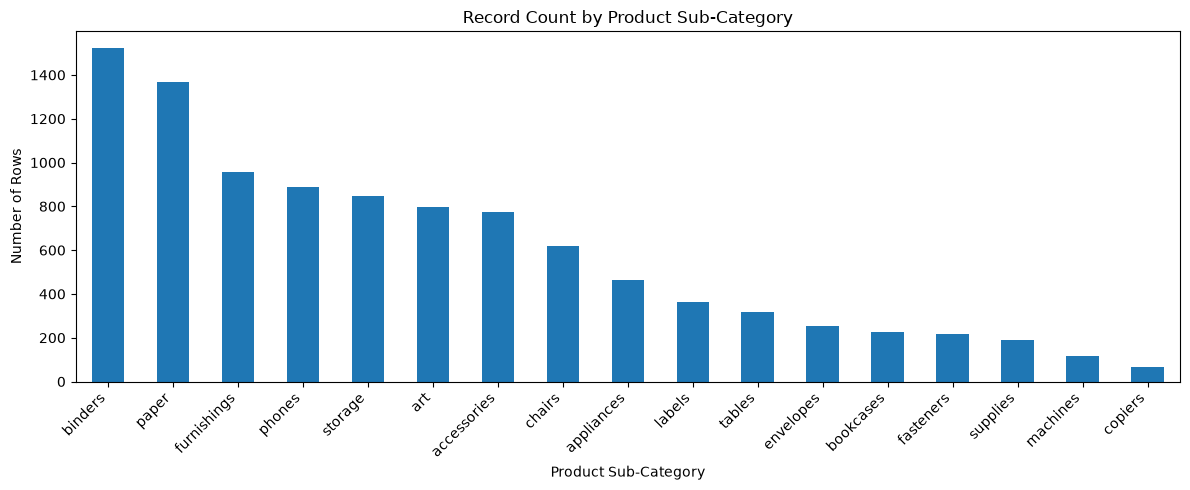

In [113]:
df['Sub-Category'].value_counts().plot(
    kind='bar',
    figsize=(12, 5),
    title='Record Count by Product Sub-Category'
)

plt.xlabel('Product Sub-Category')
plt.ylabel('Number of Rows')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [115]:
print("Order Date Range:")
print("Earliest Order Date:", df['Order Date'].min())
print("Latest Order Date:", df['Order Date'].max())


Order Date Range:
Earliest Order Date: 2014-01-03 00:00:00
Latest Order Date: 2017-12-30 00:00:00


In [121]:
print("\nShip Date Range:")
print("Earliest Ship Date:", df['Ship Date'].min())
print("Latest Ship Date:", df['Ship Date'].max())




Ship Date Range:
Earliest Ship Date: 2014-01-07 00:00:00
Latest Ship Date: 2018-01-05 00:00:00


In [123]:
print("Order Count by Year:")

yearly_orders = df['Order Date'].dt.year.value_counts().sort_index()

print(yearly_orders)

Order Count by Year:
Order Date
2014    1993
2015    2102
2016    2587
2017    3312
Name: count, dtype: int64


In [125]:
print("Order Count by Month:")

monthly_orders = (
    df['Order Date']
    .dt.month
    .value_counts()
    .sort_index()
)

print(monthly_orders)

Order Count by Month:
Order Date
1      381
2      300
3      696
4      668
5      735
6      717
7      710
8      706
9     1383
10     819
11    1471
12    1408
Name: count, dtype: int64


Plotting Order Count by Month


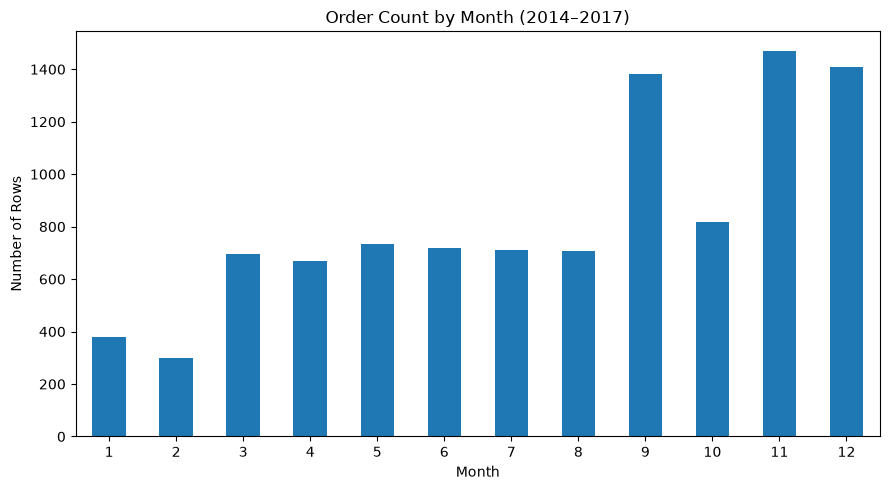

In [127]:
print("Plotting Order Count by Month")

monthly_orders.plot(
    kind='bar',
    figsize=(9, 5),
    title='Order Count by Month (2014–2017)'
)

plt.xlabel('Month')
plt.ylabel('Number of Rows')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [129]:
print("Order Count by Year and Month:")

year_month_orders = (
    df.groupby([
        df['Order Date'].dt.year,
        df['Order Date'].dt.month
    ]).size()
)

print(year_month_orders)

Order Count by Year and Month:
Order Date  Order Date
2014        1              79
            2              46
            3             157
            4             135
            5             122
            6             135
            7             143
            8             153
            9             268
            10            159
            11            318
            12            278
2015        1              58
            2              64
            3             138
            4             160
            5             146
            6             138
            7             140
            8             159
            9             293
            10            166
            11            324
            12            316
2016        1              89
            2              83
            3             163
            4             170
            5             225
            6             199
            7             201
            8   

Monthly Order-Line Counts by Year:
Order Date  2014  2015  2016  2017
Order Date                        
1             79    58    89   155
2             46    64    83   107
3            157   138   163   238
4            135   160   170   203
5            122   146   225   242
6            135   138   199   245
7            143   140   201   226
8            153   159   176   218
9            268   293   363   459
10           159   166   196   298
11           318   324   370   459
12           278   316   352   462


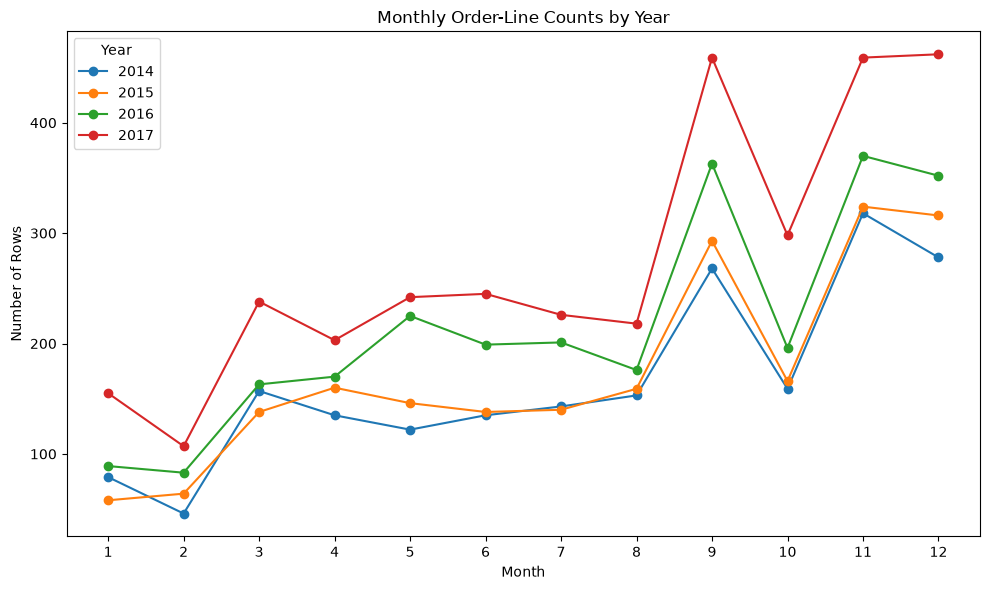

In [131]:
import matplotlib.pyplot as plt

monthly_trend = df.groupby([
    df['Order Date'].dt.month,
    df['Order Date'].dt.year
]).size().unstack()

print("Monthly Order-Line Counts by Year:")
print(monthly_trend)

monthly_trend.plot(
    kind='line',
    marker='o',
    figsize=(10, 6),
    title='Monthly Order-Line Counts by Year'
)

plt.xlabel('Month')
plt.ylabel('Number of Rows')
plt.xticks(range(1, 13))
plt.legend(title='Year')
plt.tight_layout()
plt.show()

Record Counts by Region:
Region
west       3203
east       2848
central    2323
south      1620
Name: count, dtype: int64


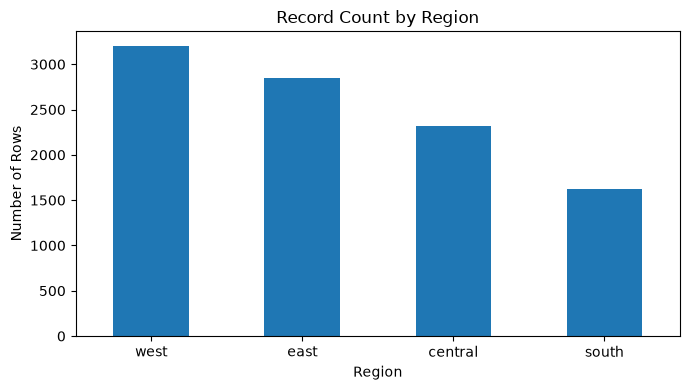

In [133]:
print("Record Counts by Region:")
print(df['Region'].value_counts())

df['Region'].value_counts().plot(
    kind='bar',
    figsize=(7, 4),
    title='Record Count by Region'
)

plt.xlabel('Region')
plt.ylabel('Number of Rows')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Top 10 States by Record Count:
State
california        2001
new york          1128
texas              985
pennsylvania       587
washington         506
illinois           492
ohio               469
florida            383
michigan           255
north carolina     249
Name: count, dtype: int64


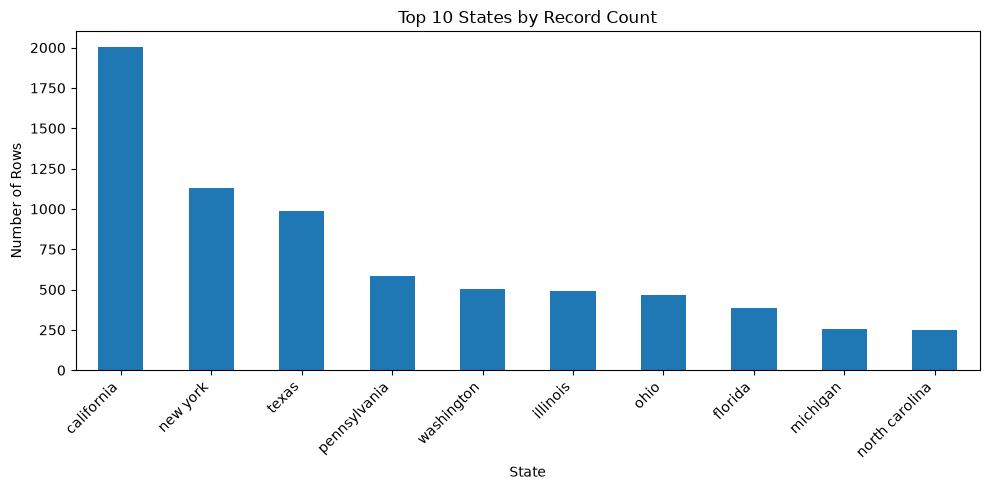

In [135]:
print("Top 10 States by Record Count:")
print(df['State'].value_counts().head(10))

df['State'].value_counts().head(10).plot(
    kind='bar',
    figsize=(10, 5),
    title='Top 10 States by Record Count'
)

plt.xlabel('State')
plt.ylabel('Number of Rows')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Top 10 Cities by Record Count:
City
new york city    915
los angeles      747
philadelphia     537
san francisco    510
seattle          428
houston          377
chicago          314
columbus         222
san diego        170
springfield      163
Name: count, dtype: int64


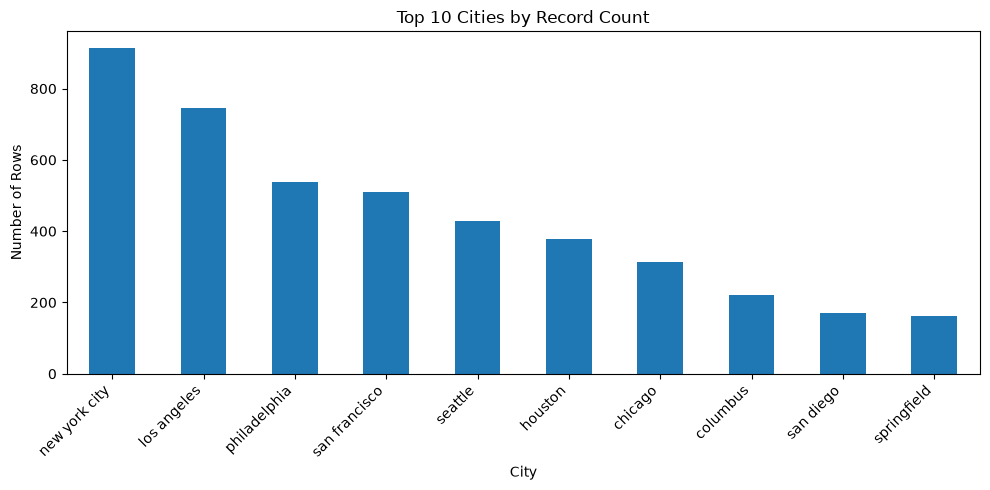

In [137]:
print("Top 10 Cities by Record Count:")
print(df['City'].value_counts().head(10))

df['City'].value_counts().head(10).plot(
    kind='bar',
    figsize=(10, 5),
    title='Top 10 Cities by Record Count'
)

plt.xlabel('City')
plt.ylabel('Number of Rows')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Correlation Matrix:
             Sales  Quantity  Discount    Profit
Sales     1.000000  0.200795 -0.028190  0.479064
Quantity  0.200795  1.000000  0.008623  0.066253
Discount -0.028190  0.008623  1.000000 -0.219487
Profit    0.479064  0.066253 -0.219487  1.000000


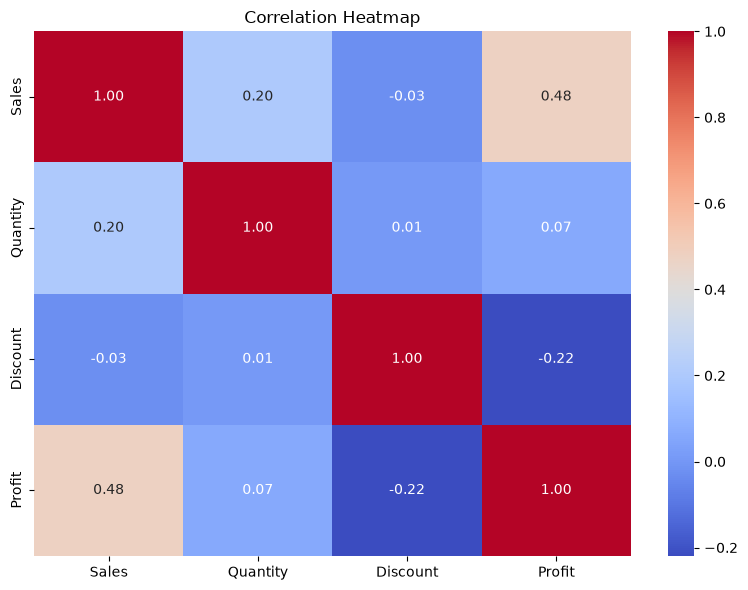

In [139]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = ['Sales', 'Quantity', 'Discount', 'Profit']

correlation = df[numeric_cols].corr()

print("Correlation Matrix:")
print(correlation)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

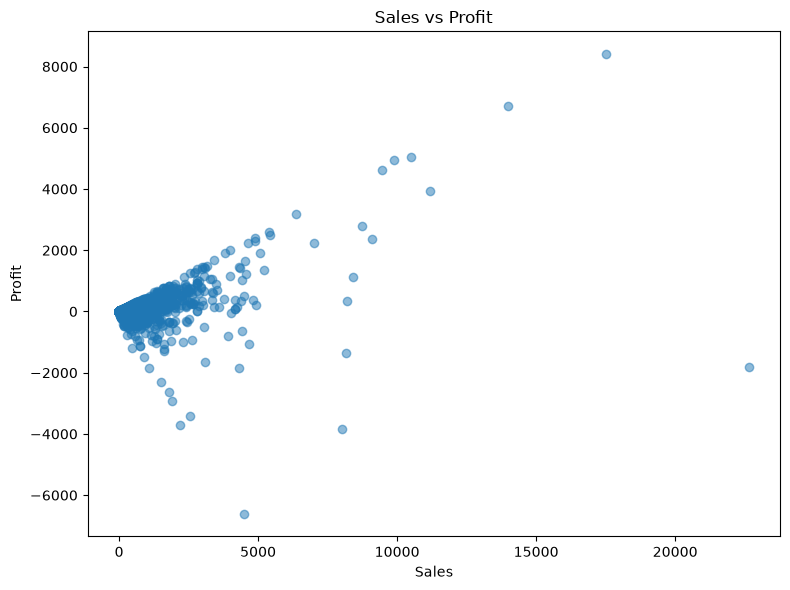

In [141]:
plt.figure(figsize=(8, 6))

plt.scatter(df['Sales'], df['Profit'], alpha=0.5)

plt.title('Sales vs Profit')
plt.xlabel('Sales')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

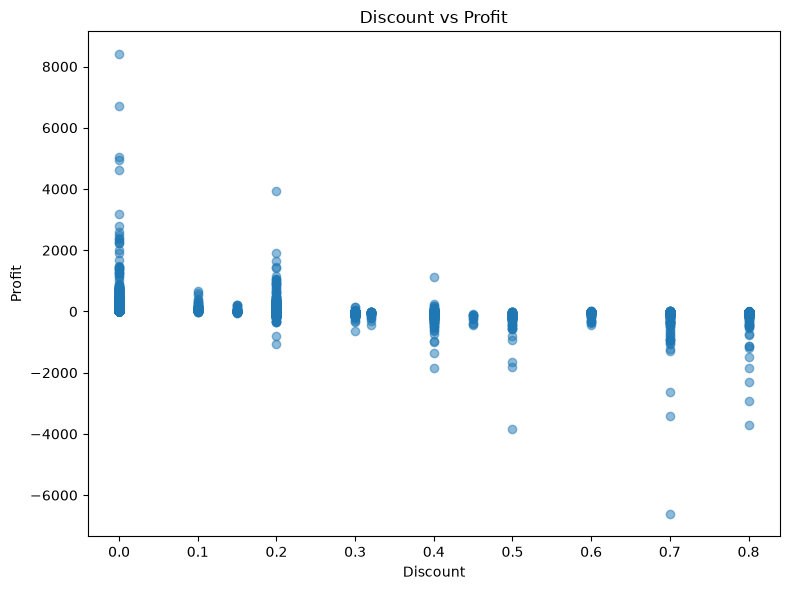

Discount vs Profit correlation:
-0.2194874563717685


In [143]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(df['Discount'], df['Profit'], alpha=0.5)

plt.title('Discount vs Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

print("Discount vs Profit correlation:")
print(df['Discount'].corr(df['Profit']))

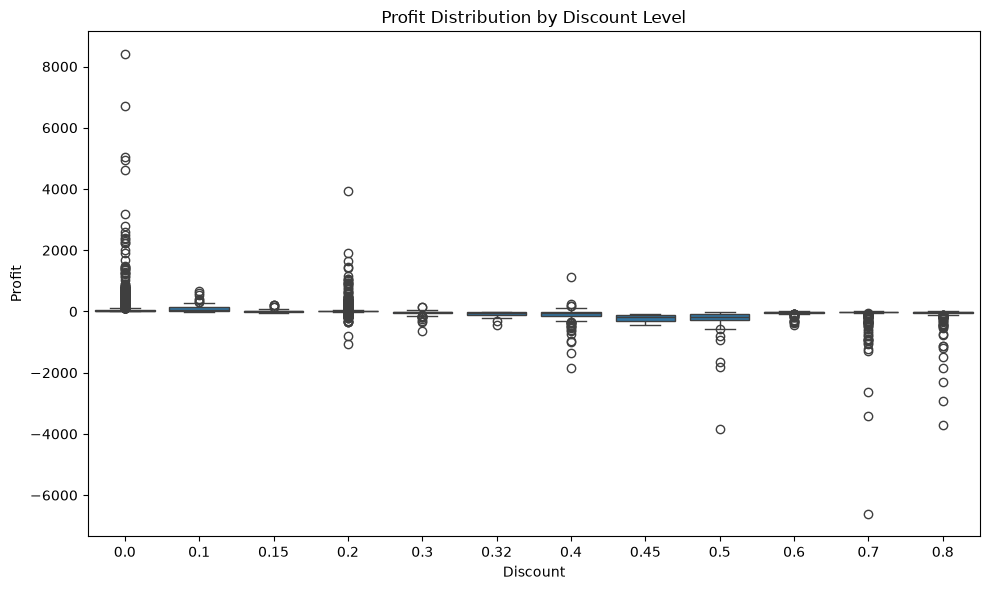

In [145]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='Discount', y='Profit')

plt.title('Profit Distribution by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

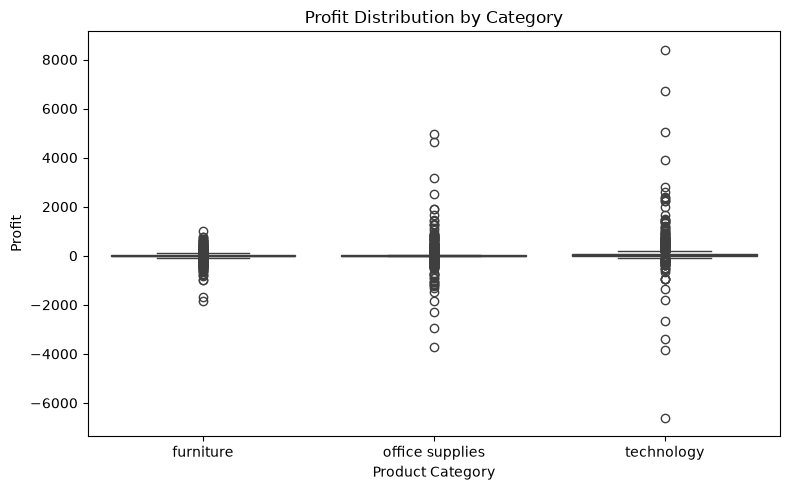


Profit Summary by Category:
                      mean   median  count
Category                                  
furniture         8.699327   7.7748   2121
office supplies  20.327050   6.8824   6026
technology       78.752002  25.0182   1847


In [147]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Category', y='Profit')

plt.title('Profit Distribution by Category')
plt.xlabel('Product Category')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

print("\nProfit Summary by Category:")
print(df.groupby('Category')['Profit'].agg(['mean', 'median', 'count']))

In [149]:
print("Category-wise Discount and Profit Analysis:")

category_analysis = (
    df.groupby("Category")
      .agg(
          avg_discount=("Discount", "mean"),
          total_sales=("Sales", "sum"),
          total_profit=("Profit", "sum"),
          avg_profit=("Profit", "mean"),
          row_count=("Profit", "count")
      )
      .round(2)
)

print(category_analysis)

Category-wise Discount and Profit Analysis:
                 avg_discount  total_sales  total_profit  avg_profit  \
Category                                                               
furniture                0.17    741999.80      18451.27        8.70   
office supplies          0.16    719047.03     122490.80       20.33   
technology               0.13    836154.03     145454.95       78.75   

                 row_count  
Category                    
furniture             2121  
office supplies       6026  
technology            1847  


In [151]:
print("Sales and Profit by Discount Level:")

discount_analysis = (
    df.groupby("Discount")
      .agg(
          total_sales=("Sales", "sum"),
          total_profit=("Profit", "sum"),
          avg_profit=("Profit", "mean"),
          row_count=("Profit", "count")
      )
      .round(2)
      .sort_index()
)

print(discount_analysis)

Sales and Profit by Discount Level:
          total_sales  total_profit  avg_profit  row_count
Discount                                                  
0.00       1087908.47     320987.60       66.90       4798
0.10         54369.35       9029.18       96.06         94
0.15         27558.52       1418.99       27.29         52
0.20        764594.37      90337.31       24.70       3657
0.30        103226.66     -10369.28      -45.68        227
0.32         14493.46      -2391.14      -88.56         27
0.40        116417.78     -23057.05     -111.93        206
0.45          5484.97      -2493.11     -226.65         11
0.50         58918.54     -20506.43     -310.70         66
0.60          6644.70      -5944.66      -43.08        138
0.70         40620.28     -40075.36      -95.87        418
0.80         16963.76     -30539.04     -101.80        300


In [153]:
print("Profit by Category and Discount Level:")

category_discount = (
    df.groupby(["Category", "Discount"])
      .agg(
          total_sales=("Sales", "sum"),
          total_profit=("Profit", "sum"),
          row_count=("Profit", "count")
      )
      .round(2)
      .reset_index()
)

print(category_discount.to_string(index=False))

Profit by Category and Discount Level:
       Category  Discount  total_sales  total_profit  row_count
      furniture      0.00    256025.27      58133.08        836
      furniture      0.10     46634.25       7111.01         76
      furniture      0.15     27558.52       1418.99         52
      furniture      0.20    216631.02       6265.95        615
      furniture      0.30     99470.35     -10695.32        222
      furniture      0.32     14493.46      -2391.14         27
      furniture      0.40     45614.41     -16187.40         75
      furniture      0.45      5484.97      -2493.11         11
      furniture      0.50     20983.47     -12871.20         54
      furniture      0.60      6644.70      -5944.66        138
      furniture      0.70      2459.38      -3894.94         15
office supplies      0.00    442150.00     130506.11       3129
office supplies      0.10      4324.15       1086.08         16
office supplies      0.20    233049.74      38038.75       2201
o

In [155]:
print("Loss-making Rows by Discount Level:")

loss_analysis = (
    df.assign(is_loss=df["Profit"] < 0)
      .groupby("Discount")
      .agg(
          total_rows=("Profit", "count"),
          loss_rows=("is_loss", "sum"),
          total_profit=("Profit", "sum")
      )
)

loss_analysis["loss_percentage"] = (
    loss_analysis["loss_rows"] / loss_analysis["total_rows"] * 100
).round(2)

print(loss_analysis.round(2))

Loss-making Rows by Discount Level:
          total_rows  loss_rows  total_profit  loss_percentage
Discount                                                      
0.00            4798          0     320987.60             0.00
0.10              94          4       9029.18             4.26
0.15              52         17       1418.99            32.69
0.20            3657        502      90337.31            13.73
0.30             227        208     -10369.28            91.63
0.32              27         27      -2391.14           100.00
0.40             206        180     -23057.05            87.38
0.45              11         11      -2493.11           100.00
0.50              66         66     -20506.43           100.00
0.60             138        138      -5944.66           100.00
0.70             418        418     -40075.36           100.00
0.80             300        300     -30539.04           100.00


In [157]:
import os

print("Current working directory:", os.getcwd())
print("CSV file exists:", os.path.exists("superstore_cleaned.csv"))
print("Full file path:", os.path.abspath("superstore_cleaned.csv"))

Current working directory: /Users/enayath/Desktop/PROJECTS
CSV file exists: True
Full file path: /Users/enayath/Desktop/PROJECTS/superstore_cleaned.csv
